In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)


In [2]:
df = pd.read_csv("../data/students.csv")

In [3]:
df.head()

,Student_ID,Attendance,Previous_Marks,Study_Hours,Assignments,Support_Needed
0,S001,92,78,4,9,0
1,S002,61,48,1,5,1
2,S003,85,72,4,8,0
3,S004,55,42,1,4,1
4,S005,76,65,3,8,0


In [4]:
df.shape

(40, 6)

In [5]:
df.columns

Index(['Student_ID', 'Attendance', 'Previous_Marks', 'Study_Hours',
       'Assignments', 'Support_Needed'],
      dtype='str')

In [6]:
df.isnull().sum()

Student_ID        0
Attendance        0
Previous_Marks    0
Study_Hours       0
Assignments       0
Support_Needed    0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df["Support_Needed"].value_counts()

Support_Needed
0    23
1    17
Name: count, dtype: int64

In [9]:
df["Baseline_Prediction"] = (
    (df["Attendance"] < 65) |
    (df["Previous_Marks"] < 50)
).astype(int)

In [10]:
df[[
    "Student_ID",
    "Attendance",
    "Previous_Marks",
    "Support_Needed",
    "Baseline_Prediction"
]].head(10)

,Student_ID,Attendance,Previous_Marks,Support_Needed,Baseline_Prediction
0,S001,92,78,0,0
1,S002,61,48,1,1
2,S003,85,72,0,0
3,S004,55,42,1,1
4,S005,76,65,0,0
5,S006,58,45,1,1
6,S007,88,81,0,0
7,S008,67,52,1,0
8,S009,94,89,0,0
9,S010,49,38,1,1


In [11]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_true = df["Support_Needed"]
y_baseline = df["Baseline_Prediction"]

print("Baseline Accuracy:", accuracy_score(y_true, y_baseline))
print("Baseline Precision:", precision_score(y_true, y_baseline))
print("Baseline Recall:", recall_score(y_true, y_baseline))
print("Baseline F1 Score:", f1_score(y_true, y_baseline))

Baseline Accuracy: 0.95
Baseline Precision: 1.0
Baseline Recall: 0.8823529411764706
Baseline F1 Score: 0.9375


In [12]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_baseline)

print(cm)

[[23  0]
 [ 2 15]]


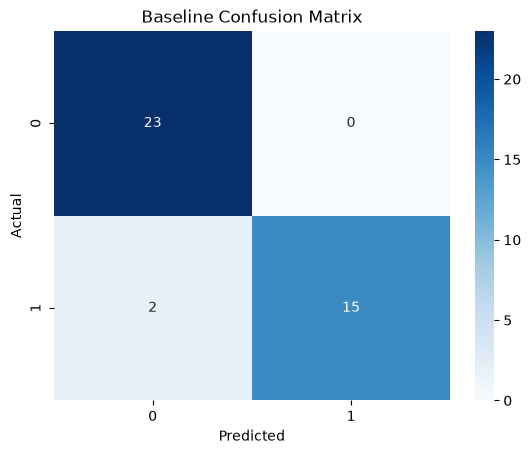

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Baseline Confusion Matrix")
plt.show()

In [14]:
features = [
    "Attendance",
    "Previous_Marks",
    "Study_Hours",
    "Assignments"
]

X = df[features]
y = df["Support_Needed"]

In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

In [16]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (30, 4)
Testing data: (10, 4)


In [17]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()

In [18]:
model.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [19]:
y_pred = model.predict(X_test)

In [20]:
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

comparison

,Actual,Predicted
0,0,0
1,0,0
2,1,1
3,0,0
4,1,1
5,0,0
6,0,0
7,1,1
8,1,1
9,0,0


In [21]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("ML Accuracy:", accuracy_score(y_test, y_pred))
print("ML Precision:", precision_score(y_test, y_pred))
print("ML Recall:", recall_score(y_test, y_pred))
print("ML F1 Score:", f1_score(y_test, y_pred))

ML Accuracy: 1.0
ML Precision: 1.0
ML Recall: 1.0
ML F1 Score: 1.0


In [22]:
cm_ml = confusion_matrix(y_test, y_pred)

print(cm_ml)

[[6 0]
 [0 4]]


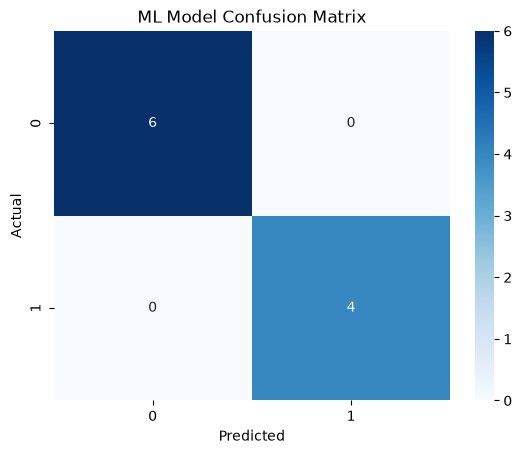

In [23]:
sns.heatmap(
    cm_ml,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("ML Model Confusion Matrix")
plt.show()

In [24]:
results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],
    "Baseline": [
        accuracy_score(y_true, y_baseline),
        precision_score(y_true, y_baseline),
        recall_score(y_true, y_baseline),
        f1_score(y_true, y_baseline)
    ],
    "ML Model": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred)
    ]
})

results

,Metric,Baseline,ML Model
0,Accuracy,0.950000,1.0
1,Precision,1.000000,1.0
2,Recall,0.882353,1.0
3,F1 Score,0.937500,1.0
